# N10 — Classical control

N8 found that covering only the black border, hiding zero data cells, costs the published neural
decoder 44 points of identity accuracy. Held out confirmed.

The open question is whether that is a property of learned decoders or of marker decoding in
general. This notebook answers it by giving a hand written classical decoder exactly the same
input: same markers, same ground truth corners, same occluder, same conditions.

**Why the answer is informative.** A classical decoder samples only the inner 36 data cells. It
never reads the border for bit values. So border occlusion should cost it nothing. If the classical
reader stays flat while the neural decoder loses 44 points, the dependence on the border is
something the network acquired during training rather than something the task requires.

**Two classical variants, because they mean different things.**

| variant | includes border validity check | what it tells you |
|---|---|---|
| bit reader only | no | fair comparison with the neural decoder, which also has no explicit check |
| full classical | yes | what a real deployed OpenCV system would do |

Validated offline on synthetic markers: the bit reader gives Hamming 0.00 at every occluder
intensity, while the border check rejects at intensity 192 and above.

Self contained. Run top to bottom. Set RUN_ON in cell 1.

## 1. Setup

In [1]:
RUN_ON = 'dev'          # 'dev' or 'heldout'

import os, sys, json, glob, zlib, subprocess, time
import numpy as np, cv2, torch, h5py
import torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view

try:
    from google.colab import drive; drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/aruco_p2'; WORK = '/content/work'
except Exception:
    BASE = os.path.expanduser('~/aruco_p2'); WORK = os.path.join(BASE, 'work')
ART, CACHE = f'{BASE}/artifacts', f'{BASE}/archives'
os.makedirs(WORK, exist_ok=True)
print('BASE =', BASE)

REPO = f'{WORK}/deeparuco'
if not os.path.isdir(REPO):
    subprocess.run(['git','clone','--depth','1',
                    'https://github.com/AVAuco/deeparuco.git', REPO], check=True)
sys.path.insert(0, REPO)
from impl.aruco import id_to_bits

def load_weights_safe(p):
    store = {}
    with h5py.File(p,'r') as f:
        root = f['model_weights'] if 'model_weights' in f else f
        def walk(g, pre=''):
            for k in g.keys():
                try: o = g[k]
                except (KeyError, OSError): continue
                q = f'{pre}/{k}'
                if isinstance(o, h5py.Dataset): store[q] = np.array(o)
                elif isinstance(o, h5py.Group): walk(o, q)
        walk(root)
    def pick(l, s):
        h = [k for k in store if f'/{l}/' in k and k.endswith(s)]
        assert len(h)==1, f'{l}:{s} -> {h}'
        return store[h[0]]
    w = {'c1_w':pick('conv2d','kernel:0'),'c1_b':pick('conv2d','bias:0'),'p1_a':pick('p_re_lu','alpha:0'),
         'c2_w':pick('conv2d_1','kernel:0'),'c2_b':pick('conv2d_1','bias:0'),'p2_a':pick('p_re_lu_1','alpha:0'),
         'c3_w':pick('conv2d_2','kernel:0'),'c3_b':pick('conv2d_2','bias:0')}
    for k,s in {'c1_w':(5,5,1,8),'c1_b':(8,),'p1_a':(28,28,8),'c2_w':(3,3,8,4),
                'c2_b':(4,),'p2_a':(12,12,4),'c3_w':(1,1,4,1),'c3_b':(1,)}.items():
        assert w[k].shape==s, f'{k}: {w[k].shape} != {s}'
    return w

DEV_ = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
splits = json.load(open(f'{ART}/splits.json'))
VIEWS  = splits['dev'] if RUN_ON=='dev' else [splits['heldout'][0]]
STRIDE = splits['benchmark_stride']
Wk  = load_weights_safe(f'{REPO}/models/dec_new.h5')
CB  = np.stack([np.asarray(id_to_bits(i),np.uint8).reshape(6,6) for i in range(250)])
ROT = np.stack([np.rot90(CB,k,axes=(1,2)).reshape(250,36) for k in range(4)]).astype(np.float32)

SHADOW = f'{WORK}/shadow'; os.makedirs(SHADOW, exist_ok=True)
for i in range(1,7):
    if not os.path.isdir(f'{SHADOW}/video_{i}'):
        subprocess.run(['tar','-xzf',f'{CACHE}/video_{i}.tar.gz','-C',SHADOW], check=True)
print(f'RUN_ON={RUN_ON} views={VIEWS} device={DEV_} cv2={cv2.__version__}')

Mounted at /content/drive
BASE = /content/drive/MyDrive/aruco_p2
RUN_ON=dev views=['video_1', 'video_2', 'video_3', 'video_4', 'video_5'] device=cuda cv2=5.0.0


## 2. Shared pipeline, same as N8

In [2]:
r_int = lambda v: int(round(v))
def ordered_corners(xs, ys):
    cx, cy = np.mean(xs), np.mean(ys)
    idx = np.argsort(np.arctan2(xs-cx, ys-cy))
    return [v for i in idx for v in (xs[i], ys[i])]
def warp32(crop, c, t=32):
    dst = np.array([[0,0],[0,t-1],[t-1,t-1],[t-1,0]], np.float32)
    src = np.clip(np.array([[c[0]*63,c[1]*63],[c[2]*63,c[3]*63],
                            [c[4]*63,c[5]*63],[c[6]*63,c[7]*63]]),0,63).astype(np.float32)
    return cv2.warpPerspective(crop, cv2.getPerspectiveTransform(src,dst), (t,t))
def get_corners(m):
    c = m['corners']
    if isinstance(c[0], dict): return np.array([[p['x'],p['y']] for p in c], np.float32)
    return np.asarray(c, np.float32).reshape(4,2)
def cell_occlusion(m32):
    s = 32/8.0; out = np.zeros((6,6), bool)
    for r in range(6):
        for c in range(6):
            out[r,c] = m32[int((r+1)*s):int((r+2)*s), int((c+1)*s):int((c+2)*s)].mean() > 127.5
    return out
def prepare(img, mask, corners):
    """Returns the 32x32 float crop used by the neural decoder, the raw uint8 crop used by the
    classical decoder, and the per cell occlusion mask."""
    x, y = corners[:,0], corners[:,1]
    mnx, mxx, mny, mxy = x.min(), x.max(), y.min(), y.max()
    ex, ey = 0.2*(mxx-mnx)+0.5, 0.2*(mxy-mny)+0.5
    mnx, mny = max(mnx-ex,0), max(mny-ey,0)
    mxx = min(mxx+ex, img.shape[1]-1); mxy = min(mxy+ey, img.shape[0]-1)
    if mxx-mnx < 8 or mxy-mny < 8: return None, None, None
    sl = (slice(r_int(mny), r_int(mxy)), slice(r_int(mnx), r_int(mxx)))
    raw = cv2.resize(img[sl], (64,64))
    nc  = ordered_corners((x-mnx)/(mxx-mnx), (y-mny)/(mxy-mny))
    f   = raw.astype(np.float32)
    f   = (f - f.min())/(f.max() - f.min() + 1e-9)
    m32 = warp32(cv2.resize(mask[sl],(64,64)), nc) if mask.any() else np.zeros((32,32), np.uint8)
    # classical gets its own warp at higher resolution, straight from the raw pixels
    dst = np.array([[0,0],[0,63],[63,63],[63,0]], np.float32)
    src = np.clip(np.array([[nc[0]*63,nc[1]*63],[nc[2]*63,nc[3]*63],
                            [nc[4]*63,nc[5]*63],[nc[6]*63,nc[7]*63]]),0,63).astype(np.float32)
    raw_warp = cv2.warpPerspective(raw, cv2.getPerspectiveTransform(src,dst), (64,64))
    return warp32(f, nc), raw_warp, cell_occlusion(m32)
def region_masks(corners, shape):
    c = corners.mean(axis=0); inner = c + (corners - c) * (6.0/8.0)
    mo = np.zeros(shape, np.uint8); cv2.fillPoly(mo, [corners.astype(np.int32)], 255)
    mi = np.zeros(shape, np.uint8); cv2.fillPoly(mi, [inner.astype(np.int32)], 255)
    return cv2.bitwise_and(mo, cv2.bitwise_not(mi)), mi
def strip_box(img, corners, level, key, mid):
    x, y = corners[:,0], corners[:,1]
    x0,x1,y0,y1 = x.min(),x.max(),y.min(),y.max(); w,h = x1-x0, y1-y0
    side = int(np.random.default_rng(zlib.crc32(f'occlusion|{level}|{key}|{mid}'.encode())).integers(0,4))
    box = [(x0,y0,x0+level*w,y1),(x1-level*w,y0,x1,y1),
           (x0,y0,x1,y0+level*h),(x0,y1-level*h,x1,y1)][side]
    a,b,c,d = [int(round(v)) for v in box]
    a,b = max(a,0),max(b,0); c,d = min(c,img.shape[1]),min(d,img.shape[0])
    return (a,b,c,d) if (c>a and d>b) else None
def make_condition(img, corners, cond, value, key, mid, level=0.50):
    if cond == 'clean': return img, np.zeros(img.shape[:2], np.uint8)
    border, data = region_masks(corners, img.shape[:2])
    if cond == 'border_only':
        paint = border
    else:
        box = strip_box(img, corners, level, key, mid)
        if box is None: return None, None
        a,b,c,d = box
        strip = np.zeros(img.shape[:2], np.uint8); strip[b:d, a:c] = 255
        paint = cv2.bitwise_and(strip, data) if cond == 'data_only' else strip
    out = img.copy(); out[paint > 0] = int(value)
    return out, paint
def pairs_for(vid):
    out = []
    for f in sorted(glob.glob(f'{SHADOW}/{vid}/*.png')):
        j = f'{SHADOW}/{vid}/corrected_annotations/{os.path.splitext(os.path.basename(f))[0]}.json'
        if os.path.exists(j): out.append((f,j))
    return out
print('pipeline ready')

pipeline ready


## 3. The classical decoder

This mirrors what OpenCV does inside detectMarkers once a marker has been located. The rectified
marker is resized to a cell grid, Otsu thresholded as a whole, and each cell is decided by majority
vote over its central region, ignoring a small margin at the cell edges. Those are OpenCV's own
defaults.

The border validity check is separated out, because it is the part that makes the two variants
behave differently.

In [4]:
CELL, MARGIN = 8, 0.13

def classical_grid(crop_gray, n=6, border=1):
    """Return the full (n+2) x (n+2) bit grid, border included."""
    side = (n + 2*border) * CELL
    img = cv2.resize(crop_gray, (side, side), interpolation=cv2.INTER_NEAREST)
    _, bw = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    g = n + 2*border; m = int(round(CELL*MARGIN))
    out = np.zeros((g, g), np.uint8)
    for r in range(g):
        for c in range(g):
            cell = bw[r*CELL+m:(r+1)*CELL-m, c*CELL+m:(c+1)*CELL-m]
            out[r, c] = 1 if cv2.countNonZero(cell) > cell.size//2 else 0
    return out

def border_valid(grid, max_white=0.30):
    ring = np.concatenate([grid[0,:], grid[-1,:], grid[1:-1,0], grid[1:-1,-1]])
    return bool(ring.mean() <= max_white)

def classical_identify(grid):
    """Nearest codeword over four rotations. Returns the id."""
    obs = grid[1:-1, 1:-1].astype(np.int16).reshape(36)
    best, bid = 99, -1
    for k in range(4):
        d = np.abs(ROT[k].astype(np.int16) - obs).sum(1)
        i = int(d.argmin())
        if d[i] < best: best, bid = int(d[i]), i
    return bid

# self test on synthetic markers
def render(i, px=200):
    g = np.zeros((8,8), np.uint8); g[1:7,1:7] = CB[i]*255
    return cv2.resize(g, (px,px), interpolation=cv2.INTER_NEAREST)
ok = sum(classical_identify(classical_grid(render(i))) == i for i in [0,42,100,238,243,249])
print(f'classical decoder self test on clean synthetic markers: {ok}/6')
assert ok == 6, 'classical decoder is broken, do not proceed'

classical decoder self test on clean synthetic markers: 6/6


## 4. The neural decoder, published weights

In [5]:
def _conv(x,w,b):
    kh,kw,_,_ = w.shape
    return np.einsum('nohckl,klci->nohi', sliding_window_view(x,(kh,kw),axis=(1,2)), w, optimize=True)+b
def _pool(x):
    N,H,Wd,Cc = x.shape; return x.reshape(N,H//2,2,Wd//2,2,Cc).max(axis=(2,4))
def neural_probs(x32, chunk=4096):
    out=[]
    for s in range(0,len(x32),chunk):
        x = np.asarray(x32[s:s+chunk],np.float32)[...,None]
        x = _pool(np.where((y:=_conv(x,Wk['c1_w'],Wk['c1_b']))>0,y,Wk['p1_a']*y))
        x = _pool(np.where((y:=_conv(x,Wk['c2_w'],Wk['c2_b']))>0,y,Wk['p2_a']*y))
        out.append(1/(1+np.exp(-np.clip(_conv(x,Wk['c3_w'],Wk['c3_b'])[...,0],-60,60))))
    return np.concatenate(out).astype(np.float32)
def neural_identify(P):
    LP = np.log(np.clip(P,1e-6,1)).reshape(len(P),36)
    LQ = np.log(np.clip(1-P,1e-6,1)).reshape(len(P),36)
    return np.stack([LP@ROT[k].T + LQ@(1-ROT[k]).T for k in range(4)]).max(0).argmax(1)
print('neural decoder ready')

neural decoder ready


## 5. Build the conditions

In [6]:
CONDS  = ['clean', 'border_only', 'data_only', 'both']
INTENS = [0, 64, 127, 192, 255]

D = {(c,v): {'n':[], 'r':[], 'id':[], 'occ':[], 'frame':[]} for c in CONDS for v in INTENS}
t0 = time.time()
for vid in VIEWS:
    for f, j in pairs_for(vid)[::STRIDE]:
        img = cv2.imread(f, cv2.IMREAD_GRAYSCALE)
        key = f'{vid}/{os.path.splitext(os.path.basename(f))[0]}'
        for m in json.load(open(j))['markers']:
            cn, mid = get_corners(m), int(m['id'])
            for cond in CONDS:
                for v in INTENS:
                    oi, om = make_condition(img, cn, cond, v, key, mid)
                    if oi is None: continue
                    x32, raw, occ = prepare(oi, om, cn)
                    if x32 is None: continue
                    d = D[(cond,v)]
                    d['n'].append((x32*255).astype(np.uint8)); d['r'].append(raw)
                    d['id'].append(mid); d['occ'].append(occ.sum()); d['frame'].append(key)
    print(f'  {vid} ({time.time()-t0:.0f}s)')
for k in D:
    for kk in D[k]: D[k][kk] = np.array(D[k][kk])

n = len(D[('clean',0)]['id'])
assert n > 2000, f'only {n} markers, data not loaded'
print(f'\n{n} markers per cell')
print(f"{'condition':>13}" + ''.join(f'{v:>8}' for v in INTENS) + '   mean data cells hidden')
for cond in CONDS:
    print(f'{cond:>13}' + ''.join(f'{D[(cond,v)]["occ"].mean():>8.1f}' for v in INTENS))
assert D[('border_only',255)]['occ'].mean() < 0.5, 'border_only is hiding data cells'
print('\nborder_only hides ~0 data cells, as designed')

  video_1 (81s)
  video_2 (142s)
  video_3 (219s)
  video_4 (296s)
  video_5 (355s)

12276 markers per cell
    condition       0      64     127     192     255   mean data cells hidden
        clean     0.0     0.0     0.0     0.0     0.0
  border_only     0.0     0.0     0.0     0.0     0.0
    data_only    17.9    17.9    17.9    17.9    17.9
         both    18.0    18.0    18.0    18.0    18.0

border_only hides ~0 data cells, as designed


## 6. Evaluate all three decoders

In [7]:
R = {}
for cond in CONDS:
    for v in INTENS:
        d = D[(cond,v)]; ids = d['id']
        # neural
        acc_n = float((neural_identify(neural_probs(d['n']/255.0)) == ids).mean())
        # classical, both variants
        pred, valid = np.empty(len(ids), int), np.empty(len(ids), bool)
        for i, raw in enumerate(d['r']):
            g = classical_grid(raw)
            pred[i] = classical_identify(g); valid[i] = border_valid(g)
        acc_c  = float((pred == ids).mean())                       # bit reader only
        acc_cb = float(((pred == ids) & valid).mean())             # with border check
        R[(cond,v)] = {'neural': acc_n, 'classical': acc_c,
                       'classical_checked': acc_cb, 'accept_rate': float(valid.mean())}
    print(f'{cond} done ({time.time()-t0:.0f}s)')

clean done (464s)
border_only done (557s)
data_only done (652s)
both done (746s)


## 7. Results

In [8]:
for cond in CONDS:
    print(f'\n=== {cond} ===')
    print(f"{'occ value':>10}{'NEURAL':>10}{'classical':>12}{'classical+chk':>15}{'accepted':>11}")
    print('-'*58)
    for v in INTENS:
        r = R[(cond,v)]
        print(f"{v:>10}{r['neural']:>10.1%}{r['classical']:>12.1%}"
              f"{r['classical_checked']:>15.1%}{r['accept_rate']:>11.1%}")
    dn = R[(cond,255)]['neural'] - R[(cond,0)]['neural']
    dc = R[(cond,255)]['classical'] - R[(cond,0)]['classical']
    print(f"  change black to white:  neural {dn*100:+.1f} pp   classical {dc*100:+.1f} pp")


=== clean ===
 occ value    NEURAL   classical  classical+chk   accepted
----------------------------------------------------------
         0     99.5%       85.5%          85.2%      99.6%
        64     99.5%       85.5%          85.2%      99.6%
       127     99.5%       85.5%          85.2%      99.6%
       192     99.5%       85.5%          85.2%      99.6%
       255     99.5%       85.5%          85.2%      99.6%
  change black to white:  neural +0.0 pp   classical +0.0 pp

=== border_only ===
 occ value    NEURAL   classical  classical+chk   accepted
----------------------------------------------------------
         0     92.3%       72.7%          72.7%     100.0%
        64     78.8%       42.7%          17.5%      26.8%
       127     66.9%       27.6%           6.7%       8.1%
       192     56.7%       15.5%           0.2%       0.2%
       255     48.5%       10.3%           0.0%       0.0%
  change black to white:  neural -43.8 pp   classical -62.5 pp

=== data_only

## 8. Verdict

BORDER ONLY condition, zero data cells hidden
  neural    : 92.3% down to 48.5%   spread 43.8 pp
  classical : 72.7% down to 10.3%   spread 62.5 pp

  clean baseline gap (neural minus classical): +14.0 pp
  (the neural decoder is expected to be better on clean markers, that is why it exists)

NOT SPECIFIC TO LEARNING. Both decoders degrade similarly, so the cause lies in the
shared preprocessing (cropping, warping, normalisation) rather than in the network.

FULL CLASSICAL with border check, for deployment realism:
  occluder   0: accepts 100.0% of markers, accuracy among all markers  72.7%
  occluder  64: accepts  26.8% of markers, accuracy among all markers  17.5%
  occluder 127: accepts   8.1% of markers, accuracy among all markers   6.7%
  occluder 192: accepts   0.2% of markers, accuracy among all markers   0.2%
  occluder 255: accepts   0.0% of markers, accuracy among all markers   0.0%
A real OpenCV system rejects markers whose border fails validation. Rejecting is
safer than mi

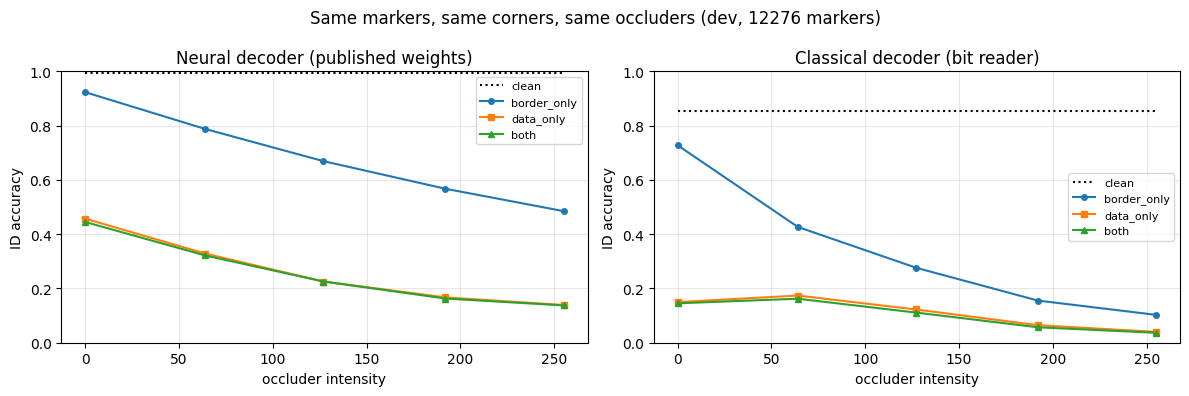


saved -> /content/drive/MyDrive/aruco_p2/artifacts/n10_classical_control_dev.json


In [9]:
bo_n = [R[('border_only',v)]['neural'] for v in INTENS]
bo_c = [R[('border_only',v)]['classical'] for v in INTENS]
cl_n = [R[('clean',v)]['neural'] for v in INTENS]
cl_c = [R[('clean',v)]['classical'] for v in INTENS]

drop_n = max(bo_n) - min(bo_n)
drop_c = max(bo_c) - min(bo_c)
base_gap = np.mean(cl_n) - np.mean(cl_c)

print('BORDER ONLY condition, zero data cells hidden')
print(f'  neural    : {max(bo_n):.1%} down to {min(bo_n):.1%}   spread {drop_n*100:.1f} pp')
print(f'  classical : {max(bo_c):.1%} down to {min(bo_c):.1%}   spread {drop_c*100:.1f} pp')
print(f'\n  clean baseline gap (neural minus classical): {base_gap*100:+.1f} pp')
print('  (the neural decoder is expected to be better on clean markers, that is why it exists)\n')

if drop_n > 0.15 and drop_c < 0.5*drop_n:
    print('LEARNED DEPENDENCE. The classical decoder is largely unaffected by border occlusion')
    print('while the neural decoder collapses on identical input. The border dependence is')
    print('acquired during training, not required by the task.')
elif drop_c >= 0.5*drop_n:
    print('NOT SPECIFIC TO LEARNING. Both decoders degrade similarly, so the cause lies in the')
    print('shared preprocessing (cropping, warping, normalisation) rather than in the network.')
else:
    print('INCONCLUSIVE: the neural decoder shows little spread here. Check section 7.')

print('\nFULL CLASSICAL with border check, for deployment realism:')
for v in INTENS:
    r = R[('border_only',v)]
    print(f'  occluder {v:>3}: accepts {r["accept_rate"]:>6.1%} of markers, '
          f'accuracy among all markers {r["classical_checked"]:>6.1%}')
print('A real OpenCV system rejects markers whose border fails validation. Rejecting is')
print('safer than misidentifying, but it is still a loss of service.')

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for cond, st in [('clean','k:'),('border_only','-o'),('data_only','-s'),('both','-^')]:
    ax[0].plot(INTENS, [R[(cond,v)]['neural'] for v in INTENS], st, ms=4, label=cond)
    ax[1].plot(INTENS, [R[(cond,v)]['classical'] for v in INTENS], st, ms=4, label=cond)
ax[0].set_title('Neural decoder (published weights)'); ax[1].set_title('Classical decoder (bit reader)')
for a in ax:
    a.set_xlabel('occluder intensity'); a.set_ylabel('ID accuracy'); a.grid(alpha=.3)
    a.legend(fontsize=8); a.set_ylim(0, 1)
plt.suptitle(f'Same markers, same corners, same occluders ({RUN_ON}, {n} markers)')
plt.tight_layout(); plt.show()

json.dump({'run_on':RUN_ON,'views':VIEWS,'n_markers':int(n),'intensities':INTENS,
           'results':{f'{c}_{v}':R[(c,v)] for c in CONDS for v in INTENS},
           'border_only_spread':{'neural':float(drop_n),'classical':float(drop_c)},
           'clean_gap_neural_minus_classical':float(base_gap)},
          open(f'{ART}/n10_classical_control_{RUN_ON}.json','w'), indent=1)
print(f'\nsaved -> {ART}/n10_classical_control_{RUN_ON}.json')